# Option A: MLP + Dropout + BatchNorm

This notebook implements a Graph Neural Network model for binary cancer classification using selected gene expression features.

Each gene is represented as a node in a graph. Edges between genes are constructed based on Pearson correlation computed from the training data only. For each patient sample, gene expression values are used as node features. The GNN learns sample-level representations by propagating information among correlated genes.

In [79]:
import pandas as pd
import numpy as np
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import matplotlib.pyplot as plt

In [80]:
#Cố định seed và chọn GPU
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [81]:
import os

BASE_DIR = r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf"

RESULT_DIR = os.path.join(os.path.dirname(BASE_DIR), "results_mlp")
os.makedirs(RESULT_DIR, exist_ok=True)

X_TRAIN_PATH = os.path.join(BASE_DIR, "X_train_rF_DEG_train_lung.csv")
X_TEST_PATH  = os.path.join(BASE_DIR, "X_test_rF_DEG_train_lung.csv")
Y_TRAIN_PATH = os.path.join(BASE_DIR, "y_train_rF_DEG_train.csv")
Y_TEST_PATH  = os.path.join(BASE_DIR, "y_test_rF_DEG_train.csv")


In [82]:
# Load dữ liệu
X_train_full = pd.read_csv(X_TRAIN_PATH, low_memory=False)
X_test       = pd.read_csv(X_TEST_PATH,  low_memory=False)

y_train_full = pd.read_csv(Y_TRAIN_PATH, low_memory=False)
y_test       = pd.read_csv(Y_TEST_PATH,  low_memory=False)

print("Raw X_train:", X_train_full.shape)
print("Raw X_test: ", X_test.shape)
print("Raw y_train:", y_train_full.shape)
print("Raw y_test: ", y_test.shape)


Raw X_train: (730, 211)
Raw X_test:  (183, 211)
Raw y_train: (730, 1)
Raw y_test:  (183, 1)


Làm sạch dữ liệu

In [83]:
def clean_feature_df(X_df):
    X_df = X_df.copy()
    X_df = X_df.loc[:, ~X_df.columns.str.contains("^Unnamed")]
    return X_df


def clean_label_df(y_df):
    y_df = y_df.copy()
    y_df = y_df.loc[:, ~y_df.columns.str.contains("^Unnamed")]

    # lấy cột cuối làm label
    y_series = y_df.iloc[:, -1]

    return y_series.astype(int)


X_train_full = clean_feature_df(X_train_full)
X_test = clean_feature_df(X_test)

y_train_full = clean_label_df(y_train_full)
y_test = clean_label_df(y_test)

print("Clean X_train:", X_train_full.shape)
print("Clean X_test:", X_test.shape)
print("Clean y_train:", y_train_full.shape)
print("Clean y_test:", y_test.shape)

print("\nTrain label distribution:")
print(y_train_full.value_counts())

print("\nTest label distribution:")
print(y_test.value_counts())

Clean X_train: (730, 211)
Clean X_test: (183, 211)
Clean y_train: (730,)
Clean y_test: (183,)

Train label distribution:
cancer_type
1    417
0    313
Name: count, dtype: int64

Test label distribution:
cancer_type
1    105
0     78
Name: count, dtype: int64


In [84]:
#Kiểm tra gene columns
gene_names = X_train_full.columns.tolist()

print("Number of selected genes:", len(gene_names))
print("First 10 genes:")
print(gene_names[:10])

Number of selected genes: 211
First 10 genes:
['ENSG00000227165', 'ENSG00000111196', 'ENSG00000240225', 'ENSG00000142089', 'ENSG00000130948', 'ENSG00000103512', 'ENSG00000142856', 'ENSG00000249307', 'ENSG00000163359', 'ENSG00000260661']


In [85]:
#Scale dữ liệu
scaler = StandardScaler()

X_train_full = pd.DataFrame(
    scaler.fit_transform(X_train_full),
    columns=X_train_full.columns
)

X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns
)

print("After scaling:")
print(X_train_full.head())

After scaling:
   ENSG00000227165  ENSG00000111196  ENSG00000240225  ENSG00000142089  \
0        -0.550418        -0.543593        -0.722269         1.096698   
1         1.040258         0.806400         0.771309        -0.644349   
2        -2.030140        -1.670805        -2.339078         1.788766   
3        -1.165872        -0.816479        -1.425339         0.146017   
4         0.144787         0.148577        -1.150702         1.304273   

   ENSG00000130948  ENSG00000103512  ENSG00000142856  ENSG00000249307  \
0        -0.453768        -0.530437        -1.754960        -0.390605   
1         0.532088         1.348822         0.616193         0.766537   
2        -1.438565        -1.760165        -2.140745        -1.589656   
3        -1.438565        -0.864603        -0.737511        -0.416133   
4        -0.589004        -1.375776        -0.917306        -0.063415   

   ENSG00000163359  ENSG00000260661  ...  ENSG00000186166  ENSG00000007392  \
0         0.904153        -1.

fit scaler trên train

transform test bằng scaler của train

không fit_transform trên test để tránh data leakage

In [86]:
#Tách validation set
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.2,
    stratify=y_train_full,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTrain labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

Train: (584, 211)
Validation: (146, 211)
Test: (183, 211)

Train labels:
cancer_type
1    334
0    250
Name: count, dtype: int64

Validation labels:
cancer_type
1    83
0    63
Name: count, dtype: int64

Test labels:
cancer_type
1    105
0     78
Name: count, dtype: int64


Chỉ dùng X_train để xây graph.

Không dùng X_test để tránh leakage.

In [87]:
#Dataset class
class GeneExpressionDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X.values, dtype=torch.float32)
        self.y = torch.tensor(y.values, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [88]:
BATCH_SIZE = 32

train_loader = DataLoader(
    GeneExpressionDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    GeneExpressionDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    GeneExpressionDataset(X_test, y_test),
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [89]:
#MLP model
class MLPDropoutBN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.model(x).squeeze(-1)


In [90]:
#Hàm tính metrics
def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)

    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    sn = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    try:
        auc = roc_auc_score(y_true, y_prob)
    except:
        auc = 0.0

    cm = confusion_matrix(y_true, y_pred)

    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        sp = tn / (tn + fp) if (tn + fp) > 0 else 0
    else:
        sp = 0

    ba = (sn + sp) / 2

    return {
        "ACC": acc,
        "Precision": precision,
        "Sensitivity/Sn": sn,
        "Specificity/Sp": sp,
        "F1": f1,
        "AUC": auc,
        "Balanced Accuracy": ba
    }

In [91]:
#Hàm train/evaluate 1 epoch
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0
    all_probs = []
    all_labels = []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        with torch.set_grad_enabled(is_train):
            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        probs = torch.sigmoid(logits).detach().cpu().numpy()

        all_probs.extend(probs)
        all_labels.extend(y_batch.detach().cpu().numpy())

        total_loss += loss.item() * len(X_batch)

    avg_loss = total_loss / len(loader.dataset)

    return avg_loss, np.array(all_labels), np.array(all_probs)


In [92]:
#Khởi tạo model, loss, optimizer
input_dim = X_train.shape[1]

model = MLPDropoutBN(input_dim).to(device)

pos_count = y_train.sum()
neg_count = len(y_train) - pos_count

pos_weight = torch.tensor(
    [neg_count / pos_count],
    dtype=torch.float32
).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print(model)
print("Positive samples:", pos_count)
print("Negative samples:", neg_count)
print("pos_weight:", pos_weight.item())


MLPDropoutBN(
  (model): Sequential(
    (0): Linear(in_features=211, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=128, out_features=1, bias=True)
  )
)
Positive samples: 334
Negative samples: 250
pos_weight: 0.7485029697418213


In [93]:
#Train MLP
EPOCHS = 100
PATIENCE = 15

best_val_auc = -1
wait = 0
history = []

for epoch in range(1, EPOCHS + 1):
    train_loss, y_train_epoch, p_train_epoch = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, y_val_epoch, p_val_epoch = run_epoch(
        model,
        val_loader,
        criterion
    )

    train_metrics = compute_metrics(y_train_epoch, p_train_epoch)
    val_metrics = compute_metrics(y_val_epoch, p_val_epoch)

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_auc": train_metrics["AUC"],
        "val_auc": val_metrics["AUC"],
        "val_ba": val_metrics["Balanced Accuracy"]
    })

    print(
        f"Epoch {epoch:03d} | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"val_auc={val_metrics['AUC']:.4f} | "
        f"val_ba={val_metrics['Balanced Accuracy']:.4f}"
    )

    if val_metrics["AUC"] > best_val_auc:
        best_val_auc = val_metrics["AUC"]
        wait = 0

        torch.save(
            model.state_dict(),
            os.path.join(RESULT_DIR, "best_mlp_model.pt")
        )
    else:
        wait += 1

    if wait >= PATIENCE:
        print("Early stopping triggered.")
        break

Epoch 001 | train_loss=0.3911 | val_loss=0.3029 | val_auc=0.9298 | val_ba=0.8382
Epoch 002 | train_loss=0.2390 | val_loss=0.2663 | val_auc=0.9509 | val_ba=0.8617
Epoch 003 | train_loss=0.1839 | val_loss=0.2344 | val_auc=0.9560 | val_ba=0.8763
Epoch 004 | train_loss=0.1670 | val_loss=0.2173 | val_auc=0.9618 | val_ba=0.8563
Epoch 005 | train_loss=0.1358 | val_loss=0.2198 | val_auc=0.9616 | val_ba=0.8801
Epoch 006 | train_loss=0.1239 | val_loss=0.2170 | val_auc=0.9627 | val_ba=0.8744
Epoch 007 | train_loss=0.0857 | val_loss=0.2514 | val_auc=0.9554 | val_ba=0.8585
Epoch 008 | train_loss=0.0715 | val_loss=0.2370 | val_auc=0.9631 | val_ba=0.8864
Epoch 009 | train_loss=0.0973 | val_loss=0.2395 | val_auc=0.9629 | val_ba=0.9223
Epoch 010 | train_loss=0.0878 | val_loss=0.2613 | val_auc=0.9577 | val_ba=0.8839
Epoch 011 | train_loss=0.0517 | val_loss=0.2236 | val_auc=0.9639 | val_ba=0.8763
Epoch 012 | train_loss=0.0371 | val_loss=0.2607 | val_auc=0.9652 | val_ba=0.9042
Epoch 013 | train_loss=0.048

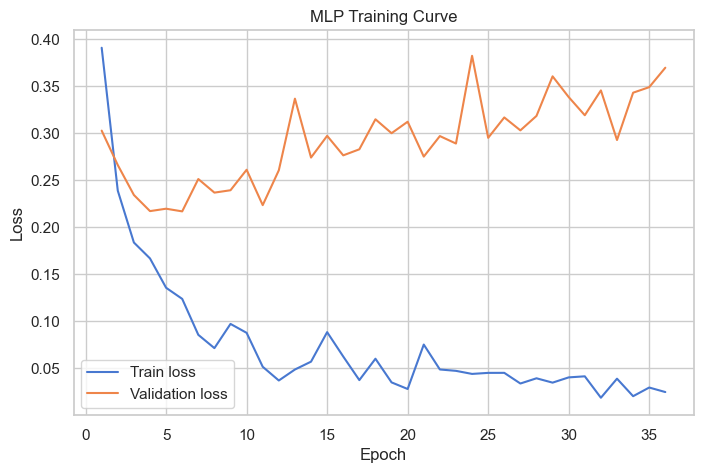

In [94]:
#Vẽ training curve
history_df = pd.DataFrame(history)

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training Curve")
plt.legend()
plt.grid(True)
plt.show()

In [95]:
#Chọn threshold tốt trên validation
model.load_state_dict(torch.load(os.path.join(RESULT_DIR, "best_mlp_model.pt")))
model.eval()

val_loss, y_val_true, y_val_prob = run_epoch(
    model,
    val_loader,
    criterion
)

fpr, tpr, thresholds = roc_curve(y_val_true, y_val_prob)

best_index = np.argmax(tpr - fpr)
best_threshold = thresholds[best_index]

print("Best threshold:", best_threshold)

val_metrics = compute_metrics(
    y_val_true,
    y_val_prob,
    threshold=best_threshold
)

val_metrics

Best threshold: 0.18691614


{'ACC': 0.9178082191780822,
 'Precision': 0.9176470588235294,
 'Sensitivity/Sn': 0.9397590361445783,
 'Specificity/Sp': np.float64(0.8888888888888888),
 'F1': 0.9285714285714286,
 'AUC': 0.9657678332377128,
 'Balanced Accuracy': np.float64(0.9143239625167336)}

In [96]:
#Test evaluation
test_loss, y_test_true, y_test_prob = run_epoch(
    model,
    test_loader,
    criterion
)

test_metrics = compute_metrics(
    y_test_true,
    y_test_prob,
    threshold=best_threshold
)

print("MLP Test Metrics")
print("=" * 50)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.6f}")

y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("\nClassification Report:")
print(classification_report(y_test_true, y_test_pred, digits=6))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_true, y_test_pred))

MLP Test Metrics
ACC: 0.857923
Precision: 0.891089
Sensitivity/Sn: 0.857143
Specificity/Sp: 0.858974
F1: 0.873786
AUC: 0.954335
Balanced Accuracy: 0.858059

Classification Report:
              precision    recall  f1-score   support

         0.0   0.817073  0.858974  0.837500        78
         1.0   0.891089  0.857143  0.873786       105

    accuracy                       0.857923       183
   macro avg   0.854081  0.858059  0.855643       183
weighted avg   0.859541  0.857923  0.858320       183


Confusion Matrix:
[[67 11]
 [15 90]]


**Lưu kết quả MLP**

In [97]:
pd.DataFrame(history).to_csv(
    os.path.join(RESULT_DIR, "mlp_training_history.csv"),
    index=False
)

pd.DataFrame([test_metrics]).to_csv(
    os.path.join(RESULT_DIR, "mlp_test_metrics.csv"),
    index=False
)

pd.DataFrame({
    "y_true": y_test_true,
    "y_prob": y_test_prob,
    "y_pred": y_test_pred
}).to_csv(
    os.path.join(RESULT_DIR, "mlp_test_predictions.csv"),
    index=False
)

with open(os.path.join(RESULT_DIR, "mlp_best_threshold.txt"), "w") as f:
    f.write(str(best_threshold))

print("MLP results saved to:", RESULT_DIR)

MLP results saved to: C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\results_mlp
